# Auditing an Image Dataset

Exploratory data analysis is not making plots. It is the disciplined work of finding out what is actually
in the data, where it is broken, what a model could learn from it that is *not* the label, and writing down
your choices, all before any training starts.

For images that work looks different from a spreadsheet, but the questions are the same. How many examples
are there, and of what? Can every one of them be read? Are the classes balanced? Do the images from one
class come from a different camera than the rest? Is the same photograph in the data twice? Do the boxes
fit inside the images they belong to? None of these questions needs a neural network, and every one of
them decides whether the network you train later measures anything at all.

This notebook builds that audit step by step on a small, deliberately messy image folder, and then asks you
to run it on Sohas, the dataset for your first assignment model.

## How to use this notebook

**How to work through it.** Run every cell in order; later cells use earlier variables. This notebook is
less about running code and more about *deciding* things, so several exercises ask you to write rather
than to program. Write your answers down. A decision you did not record is a decision you cannot defend
later.

**Time.** Sections 1 to 11 are the lesson: about 2.5 hours including the exercises. Sections 12 and 13
(the Sohas dataset, and the start of your own audit) are homework after it: half an hour of reading and
unpacking, and then the audit itself. Before you start, copy the two zip files from Brightspace into `data/raw/`: `messy-cifar10.zip` for
sections 1 to 11 and `sohas_classification.zip` for sections 12 and 13. Every cell runs in seconds.

**The example data.** Section 1 unpacks a folder of about a thousand small images from four CIFAR-10
classes that was damaged on purpose, in ways that real image datasets are damaged: broken files, stray
files, duplicates, mixed sizes and colour modes, and a second camera that is not spread evenly over the
classes. You are not told the full list. Finding it is the point.

**What you will be able to do afterwards.** Take an unfamiliar image dataset, find out what is in it, find
the problems, choose a defensible treatment for each, and write down why. Section 12 hands you Sohas, the real dataset,
and section 13 asks you to start exactly that on it: the first chapter of the final image assignment.

## Learning objectives

After this notebook, you can:

- recognise a dataset's layout on sight (`ImageFolder`, CIFAR-10's packed batches as
  `images/`/`labels/` pairs) and know that the loading code has to match that structure;
- turn a folder of images into a table with one row per file, and say what one row (one image, one
  object, one recording) represents;
- find files that are not images or cannot be decoded, and decide what to do with them;
- describe a dataset with counts and distributions: class balance, image sizes and aspect ratios, colour
  modes, brightness and contrast;
- spot a *shortcut*: a property such as camera, brightness or file format that separates the classes
  without having anything to do with the label;
- find exact and near-duplicate images, and explain why they matter for every split you make later;
- explain how a picture of the data can mislead through sampling, binning or resizing;
- name the responsible-use questions that images of people raise;
- keep a decision log that another person could follow;
- unpack a provided dataset to a known place without editing it, and read its licence and its file names
  for what they say about where the images come from.

## 1. Setup and the example data

The first cell loads the libraries and finds the project folder. **Pillow** (`PIL`) is the standard Python
library for opening images; it comes with torchvision, which is already in this project's environment.

### Dataset layouts: the structure decides how you load it

Before any code: most image datasets on disk are one of a few shapes, and which shape you have decides
which loader, or which code you write yourself, can read it.

**`ImageFolder`.** The layout of the folder this notebook audits: one folder per class, images directly
inside, nothing else.

```text
messy_images/
    cat/
        img_0001.png
        img_0002.png
        ...
    dog/
        ...
    truck/
        ...
```

The folder name *is* the label: there is no separate label file to read. PyTorch's
`torchvision.datasets.ImageFolder` reads exactly this shape: give it the root folder, and
it walks the subfolders and builds `(image, label)` pairs from their names. It is also exactly what a
manual walk like section 3's `inventory` function does, which is why this layout is worth recognising on
sight.

Two properties of this layout are also weaknesses, and each is something to check in an audit:

- **There is no label file.** No CSV, no annotation, so there is nothing to cross-check a label against.
  Whoever dropped a file into `dog/` decided that it is a dog.
- **Every file with an image extension counts, and nothing is checked.** `ImageFolder` walks the subfolders
  and takes each such file as an example. A `.txt` or a hidden `.DS_Store` is skipped silently; a `.jpg` that
  does not decode is not noticed until the training loop reaches it, hours later. Section 4 is how you find
  both before that happens.

The class *index* that a network predicts is simply the alphabetical position of the folder name: in the
example above `cat` is 0, `dog` is 1 and `truck` is 2. Rename a folder and every label number shifts.

**CIFAR-10.** Not a folder of images at all. It ships as a handful of pickled binary batches inside one
`.tar.gz` (`data_batch_1` … `data_batch_5` for training, `test_batch` for testing), each one a dictionary
holding a numpy array of pixels and a list of integer labels. There are no per-class folders and no
filenames to read a label from. The label sits inside the pickle, next to the pixels it belongs to.
`torchvision.datasets.CIFAR10`, used in notebook `03`, is a loader *specific to this format*: it unpickles those
batches and hands back `(image, label)` pairs the same way `ImageFolder` does, but the code behind it is
completely different, because the structure on disk is completely different. An `ImageFolder` cannot open
a `.tar.gz` of pickles, and a CIFAR-10 loader cannot open a folder of JPEGs: the loader has to match the
structure, never the other way round.

**The split is part of the structure too.** Datasets usually arrive already divided into training and
test data (often validation as well), and *where* that split lives depends on the format. CIFAR-10 bakes
it into separate files: `data_batch_*` is train, `test_batch` is test, chosen with the `train=`
argument. An `ImageFolder` dataset instead usually encodes the split as another level of folders above the
class, `train/cat/`, `train/dog/`, `val/cat/`, `val/dog/`, because `ImageFolder` itself knows nothing about
splits: point it at one folder and it gives you one dataset. Knowing where that boundary sits matters for
this audit: a duplicate that crosses it (section 8, exercise 4) is not a curiosity, it is leaked test data.

In [58]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
raw_dir = project_root / "data" / "raw"                  # downloads go here; git ignores everything under data/
archive = raw_dir / "messy-cifar10.zip"                  # the zip from Brightspace goes here
messy_dir = project_root / "data" / "messy_images"       # the folder this notebook audits, unpacked from the zip
print("project root:", project_root)

project root: c:\Users\marjo\OneDrive\Documents\P2


### The example data: a zip from Brightspace

The folder this notebook audits is called `messy_images`. It holds about a thousand small colour images
from four CIFAR-10 classes, the same 32 by 32 pictures notebook `03` trained on, with one folder per
class. It reaches you as a single zip file, `messy-cifar10.zip`, the way a dataset reaches you in practice.

**Before you run the next cells:** download `messy-cifar10.zip` from Brightspace and copy it into
`data/raw/` of this project. Do not unzip it yourself; the notebook does that.

Everything under `data/` is ignored by git, so neither the zip nor the unpacked folder ends up in your
repository.


In [59]:
if messy_dir.exists():
    print("data folder:", messy_dir, "(already unpacked)")
else:
    print("archive:    ", archive, "(found)" if archive.exists() else "(MISSING: copy the zip into data/raw first)")


data folder: c:\Users\marjo\OneDrive\Documents\P2\data\messy_images (already unpacked)


Python's `zipfile` module reads the archive without any external tool. The zip holds the four class
folders and nothing above them, so the notebook unpacks it *into* `messy_dir`. The cell can be run again at
any time: if the folder is already there, nothing is touched.

**The unpacked folder is never edited.** The audit that follows only reads it. Your decisions about the
files you find live in code and in your report, not in a folder that no longer matches the zip it came from.


In [60]:
import zipfile

if messy_dir.exists():
    print(f"{messy_dir} already exists, reusing it. Delete the folder to unpack again.")
elif archive.exists():
    with zipfile.ZipFile(archive) as zf:
        zf.extractall(messy_dir)
    print(f"unpacked {archive.name} into {messy_dir}")
else:
    raise FileNotFoundError(f"Copy messy-cifar10.zip from Brightspace into {raw_dir} and run this cell again.")


c:\Users\marjo\OneDrive\Documents\P2\data\messy_images already exists, reusing it. Delete the folder to unpack again.


You have been handed a folder called `messy_images`, with
the message *"four classes of photos, ready for training"*. Your job is to find out whether that is true.

Before turning this into a table, just look at it. Open a few of the actual files in each class folder, not to analyze anything yet, just to get a feeling for what is actually in there, the way you would scroll through a handful of photos on a USB stick someone handed you.

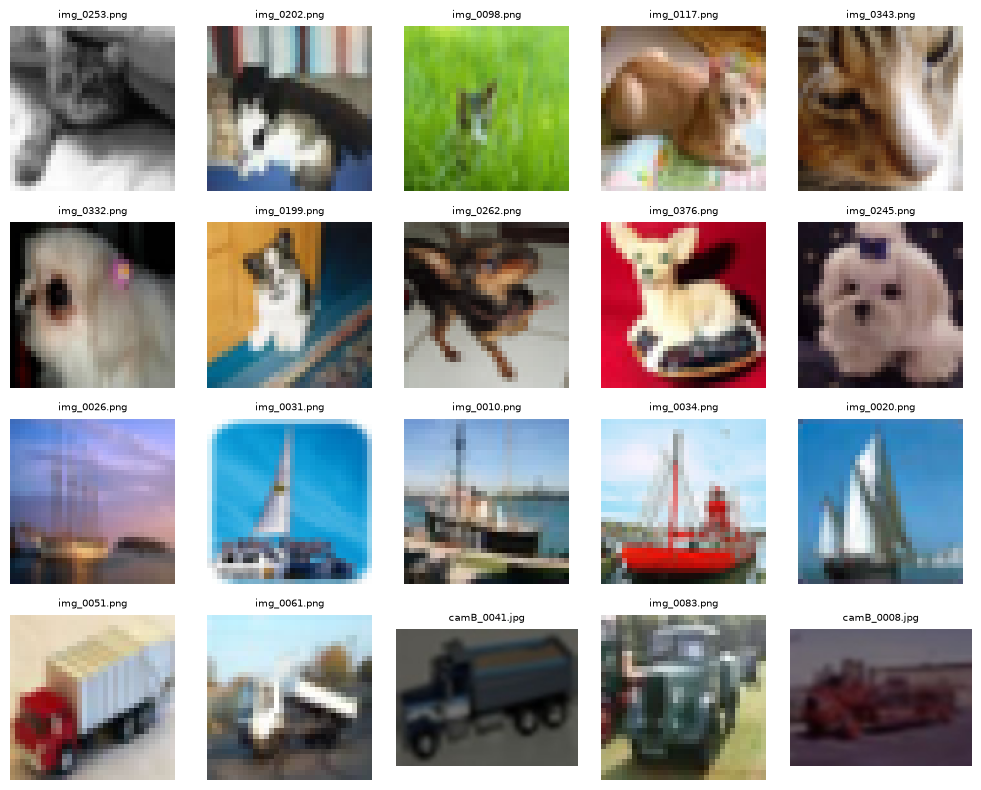

In [61]:
rng = np.random.default_rng(0)
classes = sorted(p.name for p in messy_dir.iterdir() if p.is_dir())

fig, axes = plt.subplots(len(classes), 5, figsize=(10, 2 * len(classes)))
for row, name in enumerate(classes):
    candidates = sorted((messy_dir / name).glob("*"))
    sample = rng.choice(candidates, size=5, replace=False)
    for col, path in enumerate(sample):
        ax = axes[row, col]
        try:
            ax.imshow(Image.open(path))
        except Exception as error:
            ax.text(0.5, 0.5, type(error).__name__, ha="center", va="center", fontsize=8)
        ax.set_title(path.name, fontsize=7)
        ax.axis("off")
    axes[row, 0].set_ylabel(name, fontsize=11, rotation=0, labelpad=35, va="center")
plt.tight_layout()
plt.show()

## 2. The audit: five questions before you train anything

The same five questions apply to every dataset, whatever is in it. For images they become:

1. **What does one example represent?** One photograph? One object in a photograph? One frame of a video,
   with dozens of near-identical neighbours? The answer decides what counts as a duplicate and how you
   split the data later.
2. **What population and conditions does it cover?** Which cameras, viewpoints, lighting, places, people,
   and period? A model only knows the conditions it has seen.
3. **What do you know about how it was collected and labelled?** Who took the images, who assigned the
   labels, following which rule? A dataset description is a claim, not a fact. Check it against the files.
4. **Can every file be read, and is every file what it claims to be?** Broken downloads, stray system
   files, duplicates, the same image under two labels.
5. **What could a model learn here that is not the label?** A camera, a background, a watermark, a file
   format, a brightness level that happens to go with one class. This is the question people skip, and the
   one that most often turns a good score into a useless model.

The rest of the notebook answers them for `messy_images`, starting with the most basic one: what is in the
folder?

## 3. From a folder to a table

A folder of images is hard to reason about. A table with **one row per file** is easy: you can count it,
sort it, group it and plot it. The function below walks the folder and records, for each file, what can be
known without looking at the picture: its class (the name of the folder it is in), its extension and
size on disk, and then tries to open it.

Two details matter. `rglob("*")` finds *every* file, including hidden ones whose names start with a dot;
an audit that only looks for `*.png` never sees the files that are not supposed to be there. And
`image.load()` forces Pillow to decode the whole image. `Image.open()` alone only reads the header, so a
file whose second half is missing would pass.

In [62]:
def class_of(path, root):
    """The label is the first folder below the root; a file directly in the root has none."""
    parts = path.relative_to(root).parts
    return parts[0] if len(parts) > 1 else "(top level)"


def inventory(root):
    """One row per file: what the file system says, and what happens when you try to decode it."""
    rows = []
    for path in sorted(p for p in root.rglob("*") if p.is_file()):
        row = {"path": path, "class": class_of(path, root), "file": path.name,
               "extension": path.suffix.lower(), "bytes": path.stat().st_size,
               "readable": False, "width": np.nan, "height": np.nan, "mode": None, "error": ""}
        try:
            with Image.open(path) as image:
                image.load()                      # decode everything, not just the header
                row.update(readable=True, width=image.width, height=image.height, mode=image.mode)
        except Exception as error:                # we want to record every failure, whatever its type
            row["error"] = f"{type(error).__name__}: {error}"[:70]
        rows.append(row)
    return pd.DataFrame(rows)


files = inventory(messy_dir)
print(f"{len(files)} files")
files.head()

1019 files


,path,class,file,extension,bytes,readable,width,height,mode,error
0,c:\Users\marjo\OneDrive\Documents\P2\data\mess...,(top level),.DS_Store,,8,False,NaN,NaN,NaN,UnidentifiedImageError: cannot identify image ...
1,c:\Users\marjo\OneDrive\Documents\P2\data\mess...,cat,camB_0002.jpg,.jpg,2058,True,128.0,96.0,RGB,
2,c:\Users\marjo\OneDrive\Documents\P2\data\mess...,cat,camB_0003.jpg,.jpg,2080,True,128.0,96.0,RGB,
3,c:\Users\marjo\OneDrive\Documents\P2\data\mess...,cat,camB_0011.jpg,.jpg,1970,True,128.0,96.0,RGB,
4,c:\Users\marjo\OneDrive\Documents\P2\data\mess...,cat,camB_0013.jpg,.jpg,2024,True,128.0,96.0,RGB,


`files` is a pandas **DataFrame**: a table with named columns. `files.head()` shows its first five rows.
Three pandas operations do most of an audit, and you will see them throughout:

- `files["class"].value_counts()`: how often each value occurs in a column;
- `files.groupby("class")["bytes"].median()`: a statistic per group;
- `pd.crosstab(files["class"], files["extension"])`: a count for every combination of two columns.

Start with the counts the folder names promise.

In [63]:
print("files per class:")
print(files["class"].value_counts().to_string())
print("\nfiles per extension:")
print(files["extension"].value_counts().to_string())
print("\nclass by extension:")
pd.crosstab(files["class"], files["extension"])

files per class:
class
dog            417
cat            410
truck          151
ship            40
(top level)      1

files per extension:
extension
.png    893
.jpg    123
          1
.db       1
.txt      1

class by extension:


extension,,.db,.jpg,.png,.txt
class,,,,,
(top level),1,0,0,0,0
cat,0,1,18,391,0
dog,0,0,15,402,0
ship,0,0,1,39,0
truck,0,0,89,61,1


Read the output rather than skimming it. Four classes were promised; there are five, because a file in
the top-level folder has become a "class" of its own. There are extensions that are not images. And the
crosstab already shows something that has nothing to do with damage: the `.jpg` files are not spread over
the classes the way the `.png` files are. Keep that in mind: section 7 comes back to it.

**Key terms.** *Inventory*: one row per file, before any decision. *Unit of observation*: what one row
represents; here, one file. *DataFrame*: pandas' table.

### Exercise 1: first inspection

**A. Look and read off** (3 minutes). How many files are there in total, and how many in each folder? Which
extensions occur, and which of them can you already tell are not images?

**B. Do it yourself** (15 minutes).

1. Compute the total size of the folder in megabytes, and the median file size per class with `groupby`.
   Which class has the largest files, and is there an obvious reason?
2. List every file whose extension is not `.png` or `.jpg`.
3. Write down, in two sentences, what one row of `files` represents and what it does *not* represent.

**C. Going further** (optional). The message said *"four classes of photos, ready for training"*. List every
claim in that sentence and say, for each, whether the table so far supports it.

In [8]:
# B. Your turn. A start for B1:
# files["bytes"].sum() / 1e6
# files.groupby("class")["bytes"].median()

<details>
<summary>Worked answer: Exercise 1</summary>

**A.** About a thousand files: `cat` and `dog` around 400 each (`dog` a few more, see section 6), `truck`
about 150, `ship` 40, and one file at the top level: 1,019 files in all. Extensions: `.png`, `.jpg`, `.db`, `.txt` and an empty
extension for `.DS_Store`. The last three are not images, whatever the folder says.

**B.**

1. The total is a few megabytes. `truck` has the largest median file size by far: its images are mostly
   `.jpg` files from a larger frame (section 5), which is the first hint that the truck folder came from
   somewhere else.
2. `Thumbs.db` in `cat`, `notes.txt` in `truck`, `.DS_Store` at the top level.
3. One row is one *file* in the folder, not one photograph (a photograph can be in the folder twice) and
   not one object (a photograph can show several). That distinction is what section 8 and the image
   assignment's split depend on.

**C.** *Four classes*: there are four folders, but five values in the class column. *Photos*: not every
file is a photo. *Ready for training*: not yet known, and section 4 already says no. A description is a
claim; the first job of an audit is to check it.

</details>

## 4. Files that are not images, or are broken

Every file that could not be decoded has `readable == False` and an error message. Filtering a DataFrame
with a condition in square brackets keeps only the rows where the condition is true:

In [64]:
unreadable = files[~files["readable"]]
print(f"{len(unreadable)} of {len(files)} files cannot be decoded\n")
unreadable[["class", "file", "bytes", "error"]]

6 of 1019 files cannot be decoded



,class,file,bytes,error
0,(top level),.DS_Store,8,UnidentifiedImageError: cannot identify image ...
410,cat,Thumbs.db,512,UnidentifiedImageError: cannot identify image ...
827,dog,img_empty.png,0,UnidentifiedImageError: cannot identify image ...
884,truck,camB_0026.jpg,1375,OSError: image file is truncated (0 bytes not ...
945,truck,camB_0130.jpg,1205,OSError: image file is truncated (4 bytes not ...
1018,truck,notes.txt,34,UnidentifiedImageError: cannot identify image ...


Three different kinds of problem hide in that list, and they deserve different treatment:

- **Not an image at all**: `Thumbs.db`, `notes.txt`, `.DS_Store`. System files and notes that came along
  when the folder was copied. Remove them from the dataset; they carry no label information. But *read*
  `notes.txt` first: a note that says a batch was not checked is information about the data.
- **An image with no content**: a file of zero bytes. Something failed when it was written or copied.
- **A truncated image**: a JPEG whose second half is missing, typically an interrupted download or copy.
  Pillow raises an error when it reaches the end. Some loaders are configured to *tolerate* truncated
  files and fill the rest with grey; then the error disappears and a half-grey photograph goes into
  training with a perfectly good label.

The tempting reaction is to delete everything in the list and move on. For a few files out of a thousand,
that is usually fine, but write down how many, from which classes, and why. If all the broken files had
come from one class, deleting them would quietly change your class balance. And if the original source
still has intact copies, re-downloading is better than deleting.

In [65]:
print(files.loc[files["file"] == "notes.txt", "path"].iloc[0].read_text())
images = files[files["readable"]].copy()       # from here on: only files that decode as images
print(f"{len(images)} readable images remain")

camera B batch - not checked yet

1013 readable images remain


**Never edit the original folder during an audit.** Build a table of what you will keep (here `images`)
and leave the files alone. Every decision then stays reversible, and the audit can be rerun from the
source.

**Key terms.** *Decode*: turn a file into pixels. *Truncated file*: a file cut off part way through.
*System file*: a file an operating system or file manager creates, not part of the data.

## 5. What the images are: class balance, size, shape and colour mode

Now describe the readable images. Four properties come first, because each one changes something later.

**Class balance.** How many images per class, as counts *and* as shares.

       images  share
class               
dog       416  0.411
cat       409  0.404
truck     148  0.146
ship       40  0.039

imbalance ratio, largest class to smallest: 10 to 1


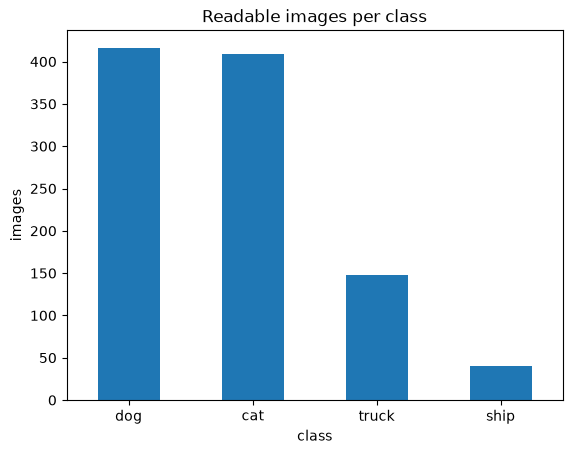

In [66]:
balance = images["class"].value_counts().to_frame("images")
balance["share"] = (balance["images"] / balance["images"].sum()).round(3)
print(balance.to_string())
print(f"\nimbalance ratio, largest class to smallest: "
      f"{balance['images'].max() / balance['images'].min():.0f} to 1")

balance["images"].plot.bar(title="Readable images per class", ylabel="images", rot=0)
plt.show()

A ratio of about ten to one between the largest and the smallest class. A model can reach more than 80%
accuracy here by never predicting `ship` at all. Notebook `05` shows why accuracy hides that, and notebook
`06` what to do about it. For now the audit's job is to report it, per class, with counts.

**Image size and shape.** Every network in this course expects images of one fixed size, so every image
will be resized. *How much* each one is resized, and whether its shape is distorted on the way, depends on
what you start from.

In [67]:
images["aspect"] = (images["width"] / images["height"]).round(2)
images["pixels"] = images["width"] * images["height"]

print("width x height, how often:")
print(images.groupby(["width", "height"]).size().sort_values(ascending=False).to_string())
print("\ncolour modes, per class:")
pd.crosstab(images["class"], images["mode"])

width x height, how often:
width  height
32.0   32.0      887
128.0  96.0      121
8.0    8.0         5

colour modes, per class:


mode,L,RGB,RGBA
class,,,
cat,9,395,5
dog,7,406,3
ship,0,40,0
truck,0,148,0


Read the two tables together.

- **Three sizes, not one.** Most images are 32×32. A group is 128×96: a different aspect ratio, 4:3
  instead of square. And a handful are 8×8: thumbnails, not photographs. Resizing an 8×8 image to 224×224
  for the ResNet of notebook `11` produces a blur that the label still calls a cat. Resizing a 4:3 image to
  a square either squashes it or crops its edges; both are decisions, not defaults.
- **Three colour modes.** `RGB` is three channels, as the networks expect. `L` is greyscale: one channel.
  `RGBA` has a fourth, transparency channel. A model that expects three channels will fail on the others,
  or worse, a loader will convert them silently. `image.convert("RGB")` makes the choice explicit; the
  report should say that you made it and for how many images.

Plot the sizes rather than only counting them: a scatter of width against height shows clusters that a
table of hundreds of sizes would hide:

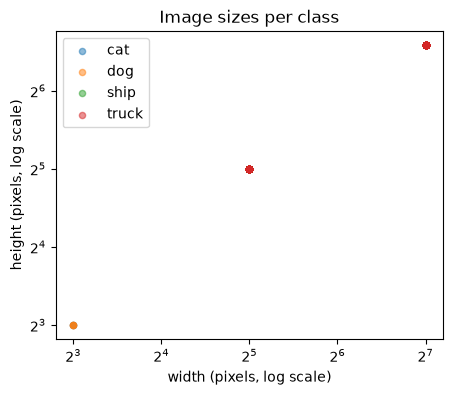

In [68]:
fig, ax = plt.subplots(figsize=(5, 4))
for name, group in images.groupby("class"):
    ax.scatter(group["width"], group["height"], label=name, alpha=0.5, s=20)
ax.set_xscale("log", base=2)
ax.set_yscale("log", base=2)
ax.set_xlabel("width (pixels, log scale)")
ax.set_ylabel("height (pixels, log scale)")
ax.set_title("Image sizes per class")
ax.legend()
plt.show()

Logarithmic axes, because image sizes vary by factors rather than by amounts: the difference between 8 and
32 pixels matters as much as the difference between 32 and 128. Each dot is an image, and many sit on top
of each other: a scatter shows *which* sizes occur, the table above shows *how often*. Use both.

**Key terms.** *Resolution*: width × height in pixels. *Aspect ratio*: width divided by height. *Colour
mode*: how many channels and what they mean, for example `RGB`, `L` (greyscale), `RGBA` (with transparency).
*Imbalance ratio*: the size of the largest class over the smallest.

### Exercise 2: what a resize will do

**A. Look and read off** (3 minutes). Which sizes occur, and in which classes? How many images are not
`RGB`, and in which classes?

**B. Do it yourself** (20 minutes).

1. Compute, per class, the share of images that are 128×96. Which class stands out?
2. Notebook `03` resizes nothing: CIFAR-10 is already 32×32. Notebook `11` resizes everything to 224×224.
   For each of the three sizes in this folder, compute the factor by which an image is scaled up to 224
   pixels wide. Which images will be enlarged more than tenfold?
3. Open one 8×8 image and one 128×96 image with `Image.open(path)` and show them with `plt.imshow`. Write
   one sentence on whether you could label each one yourself.

**C. Going further** (optional). Write a function that resizes a 4:3 image to a square in two ways, by
squashing (`resize((s, s))`) and by centre-cropping first, and show both next to each other. Which would
you choose for a truck, and would your answer change for a person?

In [14]:
# B. Your turn. A start for B1:
# images["is_128x96"] = (images["width"] == 128) & (images["height"] == 96)
# images.groupby("class")["is_128x96"].mean()

<details>
<summary>Worked answer: Exercise 2</summary>

**A.** 32×32 everywhere; 128×96 in every class but far more often in `truck`; 8×8 only in `cat` and `dog`.
Sixteen greyscale (`L`) and eight `RGBA` images, all in `cat` and `dog`.

**B.**

1. Around 60% of the truck images are 128×96, against a few per cent in the other classes. Whatever made
   those images (section 7 calls it camera B) made mostly trucks.
2. 32 → 224 is a factor of 7, 128 → 224 a factor of 1.75, 8 → 224 a factor of 28. The thumbnails are
   enlarged 28 times: the result is a smooth blur with almost no information left. Whether to keep them is
   a decision for the log: removing five images costs little, keeping them teaches the model that a blur
   can be a cat.
3. Most people can label the 128×96 image and few can label the 8×8 one with confidence. If a human cannot
   label it, the label is a guess the model will be trained to repeat.

**C.** Squashing keeps everything in the frame and distorts proportions; cropping keeps proportions and may
cut off the object. For a long vehicle, cropping can remove the very part that makes it a truck. For a
person, squashing changes body proportions in a way that is not neutral if body shape is anywhere near the
question. There is no default that is right for every class, which is why the choice belongs in the log.

</details>

## 6. Pixel statistics: brightness, contrast and colour

The table so far describes files. Now describe the pixels. Three numbers per image are enough to start:

- **brightness**: the mean pixel value, from 0 (black) to 1 (white);
- **contrast**: the standard deviation of the pixel values, which measures how much the image varies around its mean;
- **colour**: the mean of each of the three channels, red, green and blue.

The function opens each readable image, converts it to RGB so that every image has three channels, and
scales the pixel values from 0–255 to 0–1, the range notebook `03` uses as well.

In [69]:
def pixel_statistics(path):
    with Image.open(path) as image:
        pixels = np.asarray(image.convert("RGB"), dtype=np.float32) / 255     # (height, width, 3)
    grey = pixels.mean(axis=2)
    return {"brightness": grey.mean(), "contrast": grey.std(),
            "red": pixels[..., 0].mean(), "green": pixels[..., 1].mean(), "blue": pixels[..., 2].mean()}


statistics = pd.DataFrame([pixel_statistics(path) for path in images["path"]], index=images.index)
images = images.join(statistics)
images.groupby("class")[["brightness", "contrast", "red", "green", "blue"]].median().round(3)

,brightness,contrast,red,green,blue
class,,,,,
cat,0.451,0.198,0.492,0.450,0.400
dog,0.443,0.201,0.485,0.457,0.407
ship,0.546,0.191,0.491,0.554,0.617
truck,0.270,0.129,0.284,0.274,0.272


A median per class hides the shape of the distribution, so plot it. A **box plot** shows, per class, the
middle half of the values as a box, the median as a line, and the range as whiskers:

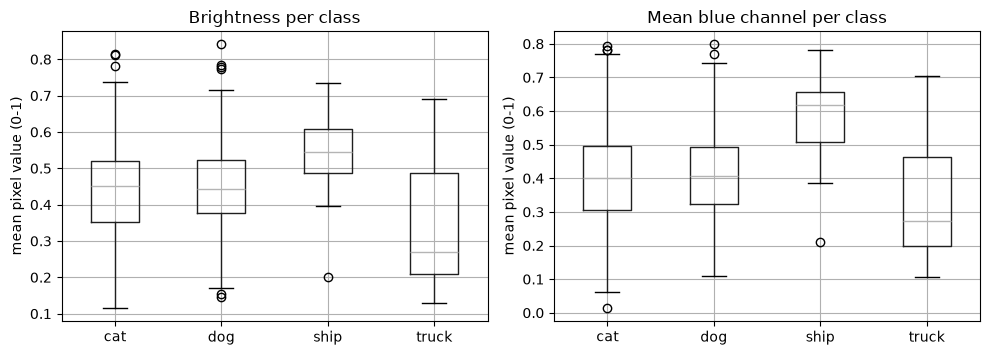

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
images.boxplot(column="brightness", by="class", ax=axes[0])
images.boxplot(column="blue", by="class", ax=axes[1])
axes[0].set_title("Brightness per class")
axes[1].set_title("Mean blue channel per class")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("mean pixel value (0-1)")
plt.suptitle("")
plt.tight_layout()
plt.show()

Two things stand out, and they are different kinds of finding.

**Ships are bluer.** That is not a defect: ships are photographed on water, under sky. But it means a
model can recognize "ship" from the background without ever looking at the ship, and will then call a
blue-sky photograph of a truck a ship. A background that goes with a class is the oldest shortcut in
computer vision.

**Trucks are darker**, and much more spread out. That one is not about trucks at all. Put brightness next
to the camera. The file name says which files came from camera B:

In [71]:
images["source"] = np.where(images["file"].str.startswith("camB"), "camera B", "camera A")
print(pd.crosstab(images["class"], images["source"]).to_string())
print()
print(images.groupby("source")["brightness"].describe()[["count", "mean", "min", "max"]].round(3).to_string())

source  camera A  camera B
class                     
cat          391        18
dog          401        15
ship          39         1
truck         61        87

          count   mean    min    max
source                              
camera A  892.0  0.463  0.154  0.841
camera B  121.0  0.216  0.116  0.320


Camera B produces dark images, and camera B produced mostly trucks. So in this folder, *dark* means
*probably a truck*. A network has no way to know that the darkness belongs to a camera and not to trucks;
it learns whatever separates the classes. Measure how far that alone gets you, a "classifier" that never
looks at a truck, only at the brightness:

In [72]:
says_truck = images["brightness"] < 0.25
is_truck = images["class"] == "truck"
caught = (says_truck & is_truck).sum() / is_truck.sum()
correct = (says_truck & is_truck).sum() / says_truck.sum()
print(f"rule 'brightness below 0.25 means truck': finds {caught:.0%} of the trucks, "
      f"and {correct:.0%} of what it calls a truck is one")

rule 'brightness below 0.25 means truck': finds 42% of the trucks, and 53% of what it calls a truck is one


A one-line rule about lighting finds a large share of the trucks, far more often right than a guess would
be, numbers notebook `05` will teach you to read properly. A convolutional network will find this rule too, in its first epoch,
and report it as truck recognition. Then it will be deployed on a camera-A truck at noon, and fail.

This is the same problem notebook `15` calls *source bias*: *the camera is in every frame, and the model
will learn it.* An audit cannot remove it, but it can find it, and the report can say plainly that the
benchmark measures camera B as much as it measures trucks. The fixes (collect camera-A trucks, balance
sources per class, evaluate per source) are decisions with costs, and they belong in the log.

**The statistics you will need later.** Notebook `03` normalizes CIFAR-10 with six numbers: a mean and a
standard deviation per channel. They come from exactly this kind of computation, over the *training*
images only. Computing them over test images as well leaks information about the test set into the
preprocessing, the same mistake as filling in missing values before splitting.

**Key terms.** *Brightness / contrast*: the mean and standard deviation of the pixel values. *Box plot*: a
distribution summarized by median, middle half and range. *Shortcut*: a property that separates the
classes in the data without being what the label is about. *Source bias*: a shortcut caused by where the
images came from.

### Exercise 3: find the shortcut

**A. Look and read off** (3 minutes). Which class has the highest median blue value, and which the lowest
median brightness? For each, say whether it is about the object or about how the images were made.

**B. Do it yourself** (25 minutes).

1. Draw the brightness box plot again, but split by `source` instead of by `class`. Then split by both
   (`by=["class", "source"]`). Is a camera-A truck darker than a camera-A cat?
2. Try the rule from the last cell with thresholds of 0.2, 0.25, 0.3 and 0.35. Make a small table of the two
   percentages. Which threshold would a lazy network pick?
3. Compute the mean and standard deviation of each channel over all readable images, as notebook `03` does
   for CIFAR-10. Then compute them over camera-A images only. How much do the numbers move?

**C. Going further** (optional). Think of one shortcut that could exist in Sohas, the dataset of the image
assignment: which objects were filmed by the researchers, which collected from the internet, with which
camera, against which background (section 12, *What the file names say*). Write down how you would
check for it with the statistics of this section.

In [19]:
# B. Your turn. A start for B1:
# images.boxplot(column="brightness", by=["class", "source"], rot=45)

<details>
<summary>Worked answer: Exercise 3</summary>

**A.** `ship` has the highest median blue value: that is about the object's surroundings, water and sky,
so it comes with the class in the real world too, but the model can still learn the background instead of
the ship. `truck` has the lowest median brightness: that is about how the images were made, and it does
not come with trucks anywhere except in this folder.

**B.**

1. By source, the two boxes barely overlap: camera B is far darker. By class *and* source, camera-A trucks
   look like camera-A cats in brightness. The darkness belongs to the camera, not to the trucks.
2. Lower thresholds catch fewer trucks with higher precision; higher thresholds catch more trucks and more
   dark pets. Whichever row you pick, the point is that *any* of them is far better than chance on a rule
   that knows nothing about trucks. A network minimizing its loss will happily use it.
3. Over all images, the means are pulled down by camera B. Over camera A only they are higher by a few
   hundredths. Small, but it shows that the normalization numbers describe a particular mix of sources;
   change the mix and they change.

**C.** For example: most knives cut from video frames recorded in one room, against a grey wall, and most
phones from product photographs on a white background. Then *blurry grey frame* means *knife* and *white
background* means *phone*, whatever is in the hand. Check: brightness, sizes and bytes per pixel per class
and per source, a crosstab of class against the source you read from the file names, and a random sample
per class side by side (section 7).

</details>

## 7. Looking at the images, and how a look can mislead

Statistics tell you where to look. They do not replace looking. The rule is simple and constantly broken:
**look at a random sample from every class**, not at the first files, and not only at the ones that look
good.

Here is what *the first files* show, the way most people glance at a folder:

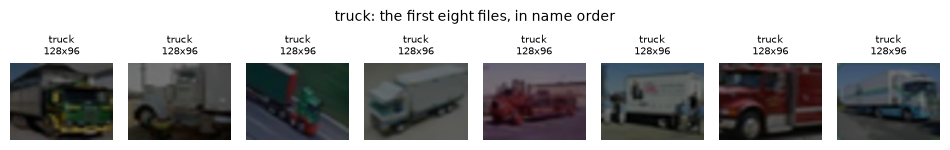

In [73]:
def show_grid(table, title, columns=8, size=1.2):
    rows = int(np.ceil(len(table) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(columns * size, rows * size + 0.4), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (_, row) in zip(axes.flat, table.iterrows()):
        with Image.open(row["path"]) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(f"{row['class']}\n{row['width']:.0f}x{row['height']:.0f}", fontsize=7)
    plt.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()


show_grid(images[images["class"] == "truck"].head(8), "truck: the first eight files, in name order")

Eight dark, enlarged trucks, all from camera B, because sorting by name puts every `camB_…` file before
the `img_…` files. Somebody glancing at this would conclude that the truck photographs are badly exposed,
when a large part of them are fine. The first files of a folder are whatever the naming happened to put
first: one camera, one batch, one day. Now a random sample, with a fixed seed so that everyone sees the
same one:

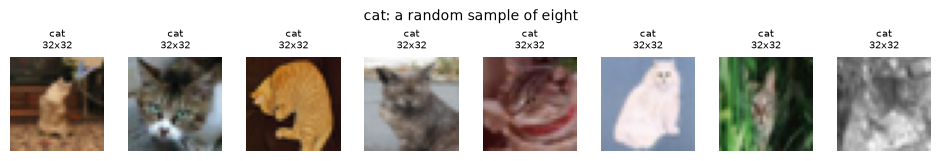

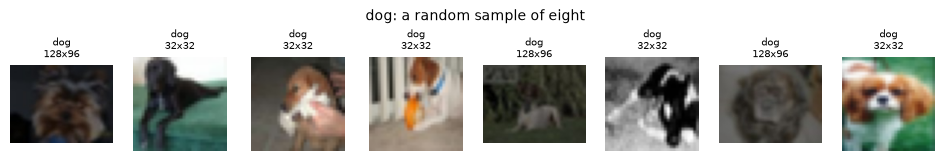

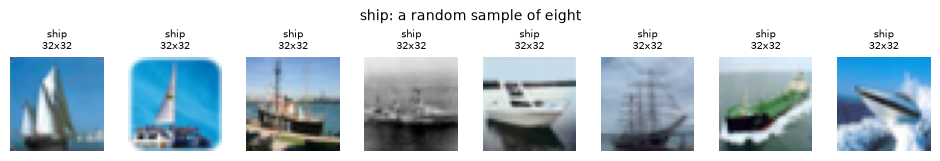

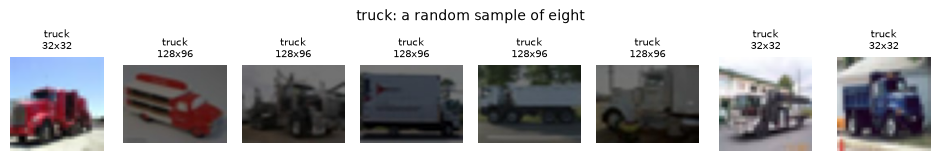

In [74]:
sample = images.groupby("class").sample(n=8, random_state=0)
for name, group in sample.groupby("class"):
    show_grid(group, f"{name}: a random sample of eight")

Three more ways a picture of the data misleads, without a single number being wrong:

- **Every thumbnail is drawn at the same size.** An 8×8 image and a 128×96 image look equally sharp in a
  grid of small squares, which is why the grid above prints the size in every title. Look at the
  smallest images at their real size before deciding they are fine.
- **Only the extremes are interesting, and they are where the problems are.** Sort by brightness,
  contrast or size, and look at the five lowest and the five highest. The darkest images, the flattest ones,
  the smallest ones: that is where broken, mislabelled and off-topic images collect.
- **A histogram's bins can hide a second group.** The brightness distribution below is the same data,
  drawn twice:

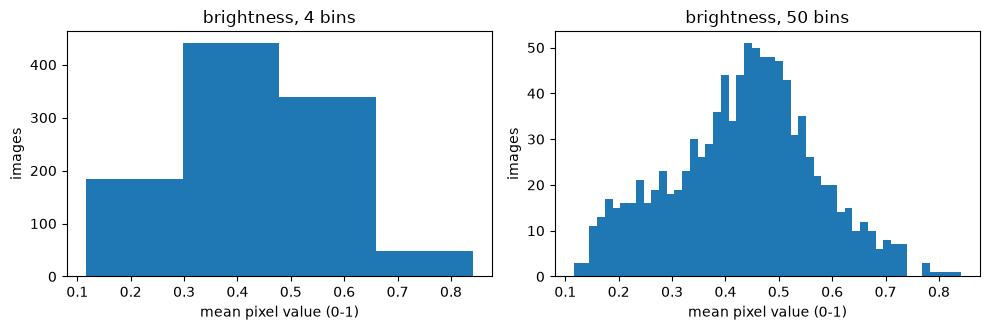

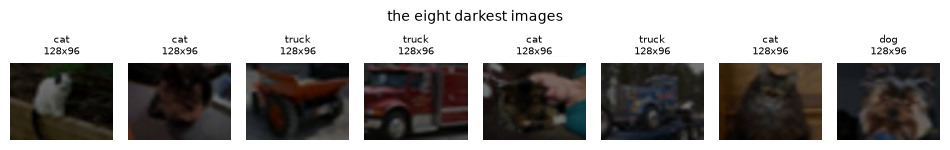

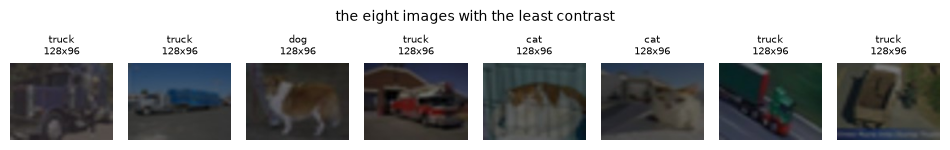

In [75]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(images["brightness"], bins=4)
axes[0].set_title("brightness, 4 bins")
axes[1].hist(images["brightness"], bins=50)
axes[1].set_title("brightness, 50 bins")
for ax in axes:
    ax.set_xlabel("mean pixel value (0-1)")
    ax.set_ylabel("images")
plt.tight_layout()
plt.show()

show_grid(images.nsmallest(8, "brightness"), "the eight darkest images")
show_grid(images.nsmallest(8, "contrast"), "the eight images with the least contrast")

With four bins, brightness looks like one lump. With fifty, a second, darker group appears: camera B. The
same numbers, a different story. Try a few bin widths before trusting the shape of any histogram, and say
in the caption which one you chose.

**Key terms.** *Random sample*: chosen by chance, with a seed so it can be reproduced. *Extremes*: the
images at the ends of a distribution; look at them first. *Bin width*: how wide each bar of a histogram
is; it changes the shape you see.

## 8. Duplicates and near-duplicates

The same photograph in a dataset twice is harmless in a spreadsheet sense: one row too many. In machine
learning it is not harmless. If one copy lands in the training set and the other in the test set, the
model is tested on an image it has already memorized, and the test score is optimistic. Notebook `10`
calls this a leak; notebooks `11`, `13`, `14` and `15` keep coming back to it, because with images it is
the default rather than the exception.

**Exact duplicates** are byte-for-byte identical files. A **hash** turns a file into a short fingerprint;
identical files get identical fingerprints, and different files, in practice, never do.

In [76]:
def file_hash(path):
    return hashlib.md5(path.read_bytes()).hexdigest()


images["md5"] = images["path"].map(file_hash)
copies = images[images.duplicated("md5", keep=False)].sort_values("md5")
print(f"{images['md5'].duplicated().sum()} files are an exact copy of another file "
      f"({copies['md5'].nunique()} distinct images involved)")

conflicts = copies.groupby("md5")["class"].nunique()
conflicting = copies[copies["md5"].isin(conflicts[conflicts > 1].index)]
print(f"{conflicting['md5'].nunique()} of them appear under more than one label:")
conflicting[["md5", "class", "file"]]

15 files are an exact copy of another file (15 distinct images involved)
3 of them appear under more than one label:


,md5,class,file
286,2a826218e9ca1029e7d6188ca1c7f535,cat,img_0280.png
825,2a826218e9ca1029e7d6188ca1c7f535,dog,img_9101.png
70,610e78e8b04576bfac601418da8a2593,cat,img_0056.png
826,610e78e8b04576bfac601418da8a2593,dog,img_9102.png
187,afa32dffd5d7117f75d4a2d6962d6b17,cat,img_0179.png
824,afa32dffd5d7117f75d4a2d6962d6b17,dog,img_9100.png


Two different problems in one table. Most copies sit in the same class: they inflate that class and
threaten every split. A few copies sit in *two* classes: the same picture is labelled both `cat` and
`dog`. At most one of those labels is right, and a model is asked to learn both. That is a **label
conflict**, and no amount of training fixes it.

**Near-duplicates** are harder: the same photograph, slightly brightened, re-compressed, resized or cropped.
Their bytes differ, so their hashes differ. A **perceptual hash** compares what the images *look like*
instead. The simplest one, the *average hash*: shrink the image to 8×8 grey pixels, and record for each of
the 64 pixels whether it is brighter than the average. Two images that look alike give almost the same 64
bits; the number of bits that differ is their **distance**.

In [77]:
def average_hash(path, size=8):
    with Image.open(path) as image:
        small = np.asarray(image.convert("L").resize((size, size)), dtype=np.float32)
    return (small > small.mean()).flatten()


hashes = np.stack([average_hash(path) for path in images["path"]])             # (images, 64) of True/False
distances = (hashes[:, None, :] != hashes[None, :, :]).sum(axis=2)               # bits that differ, every pair
first, second = np.triu_indices(len(images), k=1)                                # every pair once
close = distances[first, second] <= 3
pairs = pd.DataFrame({"a": images["file"].to_numpy()[first[close]], "class_a": images["class"].to_numpy()[first[close]],
                      "b": images["file"].to_numpy()[second[close]], "class_b": images["class"].to_numpy()[second[close]],
                      "distance": distances[first, second][close],
                      "same_bytes": images["md5"].to_numpy()[first[close]] == images["md5"].to_numpy()[second[close]]})
near = pairs[~pairs["same_bytes"]]
print(f"{len(pairs)} pairs within distance 3; {len(near)} of them are not exact copies")
near.sort_values("distance").head(12)

41 pairs within distance 3; 26 of them are not exact copies


,a,class_a,b,class_b,distance,same_bytes
3,img_0019.png,cat,img_8001.png,cat,0,False
6,img_0132.png,cat,img_8002.png,cat,0,False
17,img_0034.png,dog,img_8008.png,dog,0,False
25,img_0120.png,dog,img_8003.png,dog,0,False
24,img_0089.png,dog,img_8004.png,dog,0,False
19,img_0044.png,dog,img_8009.png,dog,0,False
16,img_0030.png,dog,img_8000.png,dog,0,False
30,img_0249.png,dog,img_8007.png,dog,0,False
36,img_0016.png,ship,img_0034.png,ship,1,False
35,img_0011.png,ship,img_0046.png,truck,2,False


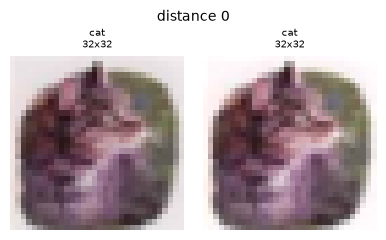

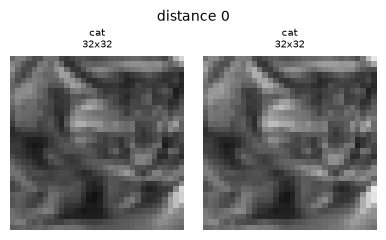

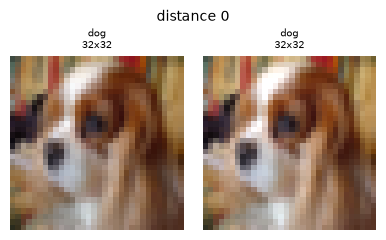

In [78]:
for _, pair in near.sort_values("distance").head(3).iterrows():
    show_grid(images[images["file"].isin([pair["a"], pair["b"]]) & images["class"].isin([pair["class_a"], pair["class_b"]])],
              f"distance {pair['distance']}", columns=2, size=2)

Look at the pairs before deciding anything. Some are a photograph and a lightly edited copy of it: true
near-duplicates. Some may be two genuinely different images that happen to have a similar layout of light
and dark: a perceptual hash finds *candidates*, not proof, and its threshold is a choice (exercise 4).

What to do with duplicates depends on what one example is supposed to be:

- **Exact copies in one class**: keep one, or keep all but make sure they always land in the same split.
- **Copies under two labels**: look at the image, decide the label, and record it, or remove all copies if
  you cannot tell.
- **Near-duplicates**: treat them as one *group*, and keep each group inside one split. That is exactly what
  notebook `14` does with clips from one recording, and what the image assignment asks of photographs of
  one scene.

**Key terms.** *Hash*: a short fingerprint of a file. *Exact duplicate*: identical bytes.
*Near-duplicate*: the same picture with small changes. *Perceptual hash*: a fingerprint of what an image
looks like. *Label conflict*: one image, two labels. *Group*: images that must stay in the same split.

### Exercise 4: duplicates and the split

**A. Look and read off** (3 minutes). How many exact copies are there, how many images appear under two
labels, and how many near-duplicate pairs did the perceptual hash find at distance 3 or less?

**B. Do it yourself** (25 minutes).

1. Change the threshold from 3 to 0, 6 and 10. Count the pairs each time and look at a few of the new ones
   at 10. Where would you put the threshold, and why?
2. Split `images` at random into 80% training and 20% test with `images.sample(frac=0.8, random_state=0)`.
   How many exact-copy groups have a member on both sides? What does that do to a test score?
3. Give every image a `group` number so that copies and near-duplicates share one, then split by group
   instead (hint: the copies share an `md5`; start from that).

**C. Going further** (optional). The average hash is fooled by a horizontal flip. Flip one image with
`image.transpose(Image.FLIP_LEFT_RIGHT)`, compute both hashes and their distance. What does that mean for a
dataset that was augmented *before* it was handed to you?

In [26]:
# B. Your turn. A start for B2:
# train = images.sample(frac=0.8, random_state=0)
# test = images.drop(train.index)
# len(set(train["md5"]) & set(test["md5"]))

<details>
<summary>Worked answer: Exercise 4</summary>

**A.** Fifteen files are exact copies: twelve within a class, and three images that also appear under
another label. Around ten near-duplicate pairs: the slightly brightened copies, plus perhaps a stray pair of different
images that look alike at 8×8.

**B.**

1. At 0 you find only images whose tiny versions are identical: the exact copies and almost nothing else.
   At 6 to 10 more and more of the pairs are merely similar compositions: a dark animal on a light
   background looks like any other at 8×8. A threshold around 3 to 5 finds the edited copies with few false
   alarms here; the honest answer is "I looked at the pairs at several thresholds and chose this one",
   written in the log.
2. Typically a few groups straddle the split. Each one is a test image the model has literally seen during
   training, so the test score is higher than on genuinely new images. With a dozen copies in a thousand
   images the effect is small; with frames from video or burst photographs, it can be most of the test set.
3. Exact copies get the group of their `md5`; near-duplicate pairs are then merged into one group. Split on
   the groups. `GroupShuffleSplit` in notebook `14` does exactly this.

**C.** The distance between an image and its mirror image is large, because the bright and dark halves swap
places. A dataset that already contains flipped copies of its own images therefore has duplicates that this
hash will not find. Ask the dataset's authors whether they augmented before publishing, and check by
flipping before hashing.

</details>

## 9. Responsible use: images of people

The cats and trucks in this notebook raise no questions about the people in them. Sohas does,
and so does the surveillance video of notebook `15`. Four questions belong in every image audit that
involves people:

- **Who is in the images, and did they agree?** People holding an object in front of a camera (some
  filmed by researchers, some in pictures collected from the internet) and people on a street camera.
  Check the dataset's licence and stated purpose, and whether educational use is allowed. Faces and other
  identifying features mean that the images are personal data. Frames you show in a report should not let
  anybody recognize the people in them: choose or blur them.
- **Who is under-represented?** Skin tones, body types, clothing, headwear worn for religious reasons,
  lighting conditions that affect some skin tones more than others, camera angles. A detector that takes a
  phone for a pistol more often in the hands of people it saw rarely in training does not treat everyone
  the same. You often cannot
  measure this directly (the labels do not say), but you can look, describe what you see, and say what you
  could not check.
- **What does the label claim?** *Pistol* is a statement about an object in a moment of an image, not about
  a person's intent, and certainly not about their guilt. Write the labels and the report so that the difference
  stays visible.
- **What happens with a mistake?** A missed pistol and a phone taken for one cost different people
  different things. Notebook `05` turns that into a threshold; the audit is where you first write it down.

**Key terms.** *Personal data*: information about an identifiable person; a recognizable face is enough.
*Under-representation*: a group that is rare in the data relative to where the model will be used.

## 10. A reusable audit function

Everything from sections 3 to 8 in one function you can point at any image folder. It is a first pass: it
does not replace looking at the images or a conversation with whoever
collected the data.

In [79]:
def audit_image_folder(root):
    """A compact first-pass report for an image folder with one subfolder per class."""
    table = inventory(root)
    readable = table[table["readable"]].copy()
    readable = readable.join(pd.DataFrame([pixel_statistics(p) for p in readable["path"]], index=readable.index))
    readable["md5"] = readable["path"].map(file_hash)
    report = readable.groupby("class").agg(
        images=("file", "size"),
        median_width=("width", "median"),
        median_height=("height", "median"),
        sizes=("width", lambda w: readable.loc[w.index].groupby(["width", "height"]).ngroups),
        non_rgb=("mode", lambda m: (m != "RGB").sum()),
        median_brightness=("brightness", "median"),
        exact_copies=("md5", lambda h: h.duplicated().sum()),
    )
    report["unreadable_files"] = table[~table["readable"]].groupby("class").size()
    return report.fillna(0).round(3)


audit_image_folder(messy_dir)

,images,median_width,median_height,sizes,non_rgb,median_brightness,exact_copies,unreadable_files
class,,,,,,,,
cat,409,32.0,32.0,3,14,0.451,5,1.0
dog,416,32.0,32.0,3,10,0.443,7,1.0
ship,40,32.0,32.0,2,0,0.546,0,0.0
truck,148,128.0,96.0,2,0,0.270,0,3.0


Note that it is run on the original folder, untouched. Audit what came in, decide what to keep in a table,
and leave the files alone; every later step then stays reproducible from the source.

## 11. The decision log, filled in

An empty template teaches nothing, so here it is completed for `messy_images`. This is the level of detail
the final assignments expect.

| Issue | Evidence | Decision | Alternatives considered | Effect on results |
|---|---|---|---|---|
| 3 files that are not images | `Thumbs.db`, `notes.txt`, `.DS_Store` (section 4) | exclude from the dataset; keep the content of `notes.txt` as documentation | delete from the folder | the stray "class" at the top level disappears; 4 classes remain |
| 3 image files that cannot be decoded | one empty `.png`, two truncated camera-B `.jpg` (section 4) | exclude; ask the source for intact copies | load truncated files with grey fill | 1 dog and 2 trucks fewer; class balance practically unchanged |
| Class imbalance, about 10 to 1 | 40 ships against about 400 cats and dogs (section 5) | keep all; report per-class metrics, not accuracy | undersample cats and dogs; collect more ships | a choice for notebook `06`; every result is reported per class |
| Three image sizes, two aspect ratios | 32×32, 128×96 and 8×8 (section 5) | resize to one size; centre-crop 4:3 images rather than squash; exclude the five 8×8 thumbnails | squash everything; keep the thumbnails | 5 images fewer; the crop rule is applied identically to every split |
| Greyscale and RGBA images | 16 `L`, 8 `RGBA`, all cats and dogs (section 5) | convert everything to RGB, explicitly | exclude them | 24 images converted; colour statistics change slightly |
| Camera B: dark, 4:3 JPEGs, mostly trucks | 87 of 148 readable trucks against a few per cent elsewhere; a brightness rule alone finds many trucks (section 6) | keep, and evaluate per source; state in the report that truck results partly measure camera B | remove camera B; brighten camera-B images | the main limitation of any benchmark on this folder, written down before training |
| Exact copies | 12 within classes (section 8) | keep one copy each | keep all and split by `md5` group | 12 images fewer; no copy can straddle a split |
| 3 images under two labels | the same file in `cat` and `dog` (section 8) | look at each, keep the correct label, remove the other copy | remove all copies | 3 dog labels removed |
| Near-duplicates | about 10 pairs at average-hash distance ≤ 3, checked by eye (section 8) | one group per pair; split by group | remove one of each pair | groups stay inside one split |

Two things to notice. Several rows end in *keep, and report* rather than *fix*: an audit does not have to
make every problem disappear, it has to make every problem visible. And the last column is the one people
skip and the one a reader needs most: what changed in the numbers because of the decision.

## 12. The Sohas dataset

The messy folder of section 1 was built to be audited. This section hands you the real thing: the
dataset of the classification assignment, as a zip from your teacher. It unpacks that zip, explains the
structure it has on disk, and stops where your audit begins. Nothing in this section counts, measures or
judges the images. That is the work of section 13, applied by you, and it is the first chapter of the
assignment.

**What you need.** The file `sohas_classification.zip` from your teacher, placed in `data/raw/` of this
project; you may have been asked to download it before the lesson. It is about 150 MB and is not in the repository. Without it the cells of this section only
print a message, and sections 12 and 13 can still be read.

### The dataset


**Sohas** stands for *Small Objects Handled Similarly*, to a weapon. The dataset was built by the DaSCI
research institute (Andalusian Research Institute in Data Science and Computational Intelligence) at the
University of Granada, for research into detecting weapons in surveillance video. The research question
behind it explains its shape: a detector that spots a pistol in a camera feed should *not* raise the alarm
for a smartphone held in the same hand, in the same way. So the dataset deliberately contains both: the
weapons, and the harmless objects that are handled like them.

It has six classes:

| Class | What it is |
|---|---|
| `pistol` | a handgun |
| `knife` | a knife |
| `smartphone` | a phone, held in the hand |
| `banknote` | a bill |
| `purse` | a purse or wallet |
| `card` | a bank card or other plastic card |

**How the images were made.** Sohas is first of all a *detection* dataset: larger photographs and video
frames in which a person handles one of these objects, with a bounding box around the object. The
classification images are those boxes **cut out** of the larger pictures. One classification image is
therefore a crop (often the object plus the hand holding it, sometimes a bit of the background), and
several crops can come from the same source picture. The source pictures are a mix of video recorded by
the researchers themselves and images collected from the internet.

**Where it comes from, and the licence.** The data is published as *Weapon detection Open Data* in the
GitHub repository [ari-dasci/OD-WeaponDetection](https://github.com/ari-dasci/OD-WeaponDetection), under a
[Creative Commons Attribution-ShareAlike 4.0](https://creativecommons.org/licenses/by-sa/4.0/) licence:
you may use and adapt it, with attribution, and share derived work under the same terms. The dataset is
described in:

> Pérez-Hernández, F., Tabik, S., Lamas, A., Olmos, R., Fujita, H., Herrera, F. (2020). *Object Detection
> Binary Classifiers methodology based on deep learning to identify small objects handled similarly:
> Application in video surveillance.* Knowledge-Based Systems, 194, 105590.
> [doi.org/10.1016/j.knosys.2020.105590](https://doi.org/10.1016/j.knosys.2020.105590)

Cite it in your report, in the README of your project and under any figure that shows the images. In
BibTeX, as the repository gives it:

```bibtex
@article{article,
  author = {Pérez, Francisco and Tabik, Siham and Castillo Lamas, Alberto and Olmos, Roberto and Fujita, Hamido and Herrera, Francisco},
  year = {2020},
  month = {02},
  pages = {105590},
  title = {Object Detection Binary Classifiers methodology based on deep learning to identify small objects handled similarly: Application in video surveillance},
  volume = {194},
  journal = {Knowledge-Based Systems},
  doi = {10.1016/j.knosys.2020.105590}
}
```

**What the licence means for you.** CC BY-SA 4.0 has two conditions. *BY*: whenever you use the data,
you name the source (the authors, the repository, the paper), link to the licence and say what was
changed. *SA*: anything you distribute that is derived from the data (a cleaned copy, a subset, a zip you
pass to a fellow student) must carry the same licence and the same attribution. Your audit report and your
trained model are your own work; the data inside them is not.

The zip you were given is itself such a derived copy. The original folders carry Spanish class names
(`billete`, `monedero`, `tarjeta`); the zip uses the English names in the table above. The file names
inside still show the Spanish words. It is also a *teaching* copy: a small number of deliberate errors,
of the kinds real datasets have, were introduced into it. Which files they are is not listed anywhere
you can see; finding them is part of your audit, next to the problems the original data has of its own.
A `LICENSE.md` at the root of the unpacked folder records the source, the licence, the citation and
these changes. Keep it with the data, and copy its attribution into your own README.

**What you are not told here.** How many images each class has, how large they are, whether they are all
readable, whether any of them appear twice, and what else than the object could tell the classes apart.
A dataset description is a claim; the audit checks it against the files.

### Unpacking the zip

Same convention as section 1: the project root is found from the notebook's location, raw downloads
live in `data/raw/`, and the folder of this dataset is `data/raw/sohas_classification/`. Everything under
`data/` is ignored by git.

In [ ]:
import zipfile                       # reads .zip files, no external tool needed
from pathlib import Path             # file paths as objects: folder / "name" joins them

import matplotlib.pyplot as plt      # plotting: the figure of random crops at the end of this section
import numpy as np                   # random numbers, to pick which crops to show
from PIL import Image                # opens the image files

# This notebook lives in notebooks/, so the project root is one folder up. Run from the root itself and
# the current folder is already the root. Building every path from the root means it works from both.
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
raw_dir = project_root / "data" / "raw"                 # all raw downloads live here
archive = raw_dir / "sohas_classification.zip"          # the zip from your teacher goes here
sohas_dir = raw_dir / "sohas_classification"            # the folder the zip unpacks to
print("project root:", project_root)

# Only a check, nothing is unpacked yet: is the data already there, or at least the zip?
if sohas_dir.exists():
    print("data folder: ", sohas_dir, "(already unpacked)")
else:
    print("archive:     ", archive, "(found)" if archive.exists() else "(MISSING - copy the zip here first)")


Python's `zipfile` module reads the archive without any external tool. Unpacking puts one folder per
class, each with its images, directly in `sohas_dir`, which is `data/raw/sohas_classification/`. The cell
is written so that it can be run again at any time: if the folder is already there, nothing is touched.

**The unpacked data is never edited.** Broken files stay broken, duplicates stay in, stray files stay where
they are. Your decisions about them live in code and in your report, where another person can read and
reverse them, not in a folder that no longer matches the zip it came from.

In [ ]:
# Three cases, in this order:
if sohas_dir.exists():                          # 1. already unpacked: touch nothing, so reruns are safe
    print(f"{sohas_dir} already exists - reusing it. Delete the folder to unpack again.")
elif archive.exists():                          # 2. the zip is there: unpack it into sohas_dir
    with zipfile.ZipFile(archive) as zf:        #    `with` closes the zip again when the block ends
        # The class folders end up directly in sohas_dir, whether the zip holds them at the top or
        # inside one folder called sohas_classification/ (then unpack one level higher).
        wrapped = all(name.startswith("sohas_classification/") for name in zf.namelist())
        zf.extractall(raw_dir if wrapped else sohas_dir)
    print(f"unpacked {archive.name} into {sohas_dir}")
else:                                           # 3. neither: say what to do, and do not crash
    print(f"put {archive.name} in {raw_dir} first; the rest of this section is skipped until then")

# The class folders: every subfolder of sohas_dir, sorted by name. The empty list when there is no
# data yet makes the cells below skip themselves.
class_dirs = sorted(p for p in sohas_dir.iterdir() if p.is_dir()) if sohas_dir.exists() else []
print("class folders:", [p.name for p in class_dirs])


### What is in the folder

Sohas classification has the `ImageFolder` layout from section 1: one folder per class, the folder name is
the label, one pool of images and no split. The two weaknesses listed there apply here as they are.

The cell below lists the first few files of each folder, and the files at the top level. It does not
count anything.


In [ ]:
# For every class folder: its first three file names in alphabetical order. This only looks at names,
# no image is opened and nothing is counted.
for class_dir in class_dirs:
    first_files = sorted(p.name for p in class_dir.iterdir())[:3]
    print(f"{class_dir.name + '/':14s}", ", ".join(first_files), ", ...")

# Files directly in the root of the dataset, next to the class folders (is_file() skips the folders).
if sohas_dir.exists():
    print("\nfiles at the top level:", sorted(p.name for p in sohas_dir.iterdir() if p.is_file()))


### Question 1: what else is in the folder?

The cell above printed the first files of each class and, at the end, the files at the top level of the
folder, next to the class folders.

- Which of those top-level files are not a class folder? Did the authors of the dataset put each of them
  there on purpose?
- Will `ImageFolder` read them? Will the `inventory` of section 3 list them, and under which class?
- What do you do with each of them, and where do you write that down?

<details>
<summary>Answer</summary>

`LICENSE.md` is meant to be there: it is the licence of the dataset. `ImageFolder` only looks inside the
class folders and never sees a file at the top level. The `inventory` of section 3 does list it, with the
class `(top level)` and as a file that does not decode as an image. Both behave correctly.

The rule that follows: every file at the top level is a question. For each one, find out what it is and who
put it there. Keep what belongs to the dataset (the licence asks for attribution), take what does not
belong out of the image table, and write each decision down, with the reason, in your decision log.

</details>


`ImageFolder` reads this layout straight away. Three things it gives you are worth knowing before you
write any audit code: `classes` (the folder names, sorted), `class_to_idx` (the number each one gets), and
indexing, which returns one `(image, label)` pair: a `PIL.Image` and an integer. There is no transform
here on purpose: you want to see the images as they are on disk, not resized.

In [ ]:
from torchvision.datasets import ImageFolder

if sohas_dir.exists():
    sohas = ImageFolder(sohas_dir)                     # builds the list of (path, label) pairs; opens no image yet
    print("classes:     ", sohas.classes)              # the folder names, sorted
    print("class_to_idx:", sohas.class_to_idx)         # the number each folder name gets: its sorted position
    image, label = sohas[0]                            # indexing opens the first image: a PIL image and an integer
    print("\none item:    ", type(image).__name__, image.size, image.mode, "-> label", label, f"({sohas.classes[label]})")
    display(image)                                     # shows the image as it is on disk (no transform was given)


### Question 2: what do the file names say?

Look at the file names in the listing above, and in the figure below, and write down everything you can
read from them.

- Is there a part of a name that repeats within a class? Does it always match the folder the file sits in?
- What could `box1` and `box2` mean, and what does that imply for the number of *photographs* behind the
  number of files?
- Do all names look alike, or do you see groups that come from different places?
- Which of these things could matter for how you split the data, and which could be a shortcut for a model?

<details>
<summary>Answer</summary>

A file name in this dataset is not random. `billete_0012_box3.jpg` is the third box cut out of the twelfth
*billete* (Spanish for banknote) source picture; `ABbframe00154_box1.jpg` is a box cut out of a frame of a
video. `1bil1mon_0001_box1.jpg` in `purse/` and `1bil1mon_0001_box2.jpg` in `banknote/` are two boxes from
*one* picture of one bill and one purse. The prefix of a name usually belongs to its class (`billete`,
`tarjeta`, `monedero`, `pistol`, `smartphone`, `knife`): a prefix that belongs to another class than the
folder it sits in is worth a look.

Two consequences for your audit:

- **What does one example represent?** (question 1 of section 2). One row in your inventory
  is one crop, not one photograph and not one scene. Several crops share a source picture, and crops from
  neighbouring video frames can be near-identical. Whether those belong in the same split is a decision
  you have to make and write down (exercise 4, and notebook `10`).
- **The source is readable from the name.** A stem that looks like a video frame and a stem that looks like
  a downloaded picture come from different places, with different cameras, lighting and backgrounds. If
  that difference lines up with a class, it is a shortcut (section 6 and exercise 3).

</details>

Before any table: look. Five random crops per class, with the file name and the size on disk.


In [ ]:
if class_dirs:
    rng = np.random.default_rng(0)        # fixed seed: everyone sees the same random crops

    # A grid with one row per class and 5 columns, one panel per crop.
    fig, axes = plt.subplots(len(class_dirs), 5, figsize=(12, 2.4 * len(class_dirs)))
    for row, class_dir in enumerate(class_dirs):
        candidates = sorted(class_dir.glob("*"))                       # every file in this class folder
        # Pick 5 different files at random. Every file is a candidate: stray and broken ones too.
        for col, path in enumerate(rng.choice(candidates, size=5, replace=False)):
            ax = axes[row, col]
            try:
                img = Image.open(path)
                ax.imshow(img)
                ax.set_title(f"{path.name}\n{img.size[0]}x{img.size[1]}", fontsize=7)   # name and size in pixels
            except Exception as error:
                # A file that cannot be opened as an image: show the kind of error in the panel instead.
                ax.text(0.5, 0.5, type(error).__name__, ha="center", va="center", fontsize=8)
                ax.set_title(path.name, fontsize=7)
            ax.axis("off")                                              # no axis numbers on an image
        # The class name, written to the left of the first panel of the row.
        axes[row, 0].text(-0.1, 0.5, class_dir.name, transform=axes[row, 0].transAxes,
                          ha="right", va="center", fontsize=10, fontweight="bold")
    plt.tight_layout()
    plt.show()


### Responsible use of these images

These are pictures of people holding weapons, some recorded by researchers who knew they were being
filmed, some collected from the internet. The four questions of section 9 all apply, and
two deserve a note now:

- **Faces and hands.** A crop can include a face. Do not put recognisable people in your report; pick
  crops that show only the object and hand, or blur.
- **What the label claims.** `pistol` says that a pistol-shaped object is in this crop. It says nothing
  about the person, their intent, or whether the object is real. Keep that distinction in the words you
  use for the classes and the errors.

The licence asks for attribution: name the dataset, the repository and the paper above in your README and
report, as `LICENSE.md` in the data folder does.

## 13. Apply it: start the audit of the Sohas dataset

Continue in the **P2_computervision** uv project from notebook `00`. Your teacher provides the dataset of
the image assignment: **Sohas**, crops of weapons and of the harmless objects that are held like them,
introduced in section 12 (the README of the course repository lists every dataset and its source).
Audit it with the methods of this notebook, and communicate what the data can and cannot tell you. **No
model training is required.**

The copy you receive is a teaching copy: a few deliberate errors were added to it, next to the problems the
original data has of its own (section 12). Nobody tells you which; that is what the audit is for.

This is not handed in on its own. It is the first chapter of the final image assignment, which you train
for in notebooks `11` and `13`: everything you find now (the classes, the sizes, the sources, the
duplicates, the crops that share a source picture) is what those notebooks build on. What you do now you
will not have to do in week 5, and what you skip now you will.

### Project setup

Keep the `main.py` of notebook `00` and add a separate `audit.py` in the same uv environment. From the
project folder:

```bash
uv add pillow numpy pandas matplotlib
```

```text
P2_computervision/
    data/
        raw/
            sohas_classification.zip
            sohas_classification/    <- unpacked as section 12 does it; never edited
            sohas_detection.zip
            sohas_detection/         <- the full pictures with their boxes, for step 7 and notebook 13
    reports/
        audit.md
        figures/
    main.py
    audit.py
    pyproject.toml
    uv.lock
    README.md
```

Keep the provided data unchanged. Your decisions live in code and in the report, not in edited files. Do
not commit the images to git, and do not put recognizable faces in your report.


### Starter for `audit.py`

Only the skeleton. The functions of this notebook are your raw material: copy them in and **adapt** them.
They were written for the messy folder of about a thousand images, and they do not all work unchanged on
Sohas. Finding out which ones do not, and why, is part of the work. Run every step on a small part of the
data first (200 files, say) before you run it on all of it.

```python
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

DATA_DIR = Path("data/raw/sohas_classification")
REPORT_DIR = Path("reports")
FIGURE_DIR = REPORT_DIR / "figures"


def inventory(root):
    """One row per file: path, class, file, extension, bytes, readable, width, height, mode, error."""
    # TODO: section 3. What is the class of a file that sits directly in the root?
    raise NotImplementedError


def add_source(table):
    """Add a column 'source' that says where an image comes from, derived from its file name."""
    # TODO: the messy folder used startswith("camB"). What do the Sohas names offer?
    raise NotImplementedError


def add_pixel_statistics(table):
    """Add brightness, contrast and the three colour means for every image that can be read."""
    # TODO: section 6
    raise NotImplementedError


def exact_duplicates(table):
    """Add an md5 column and return the files that are an exact copy of another file."""
    # TODO: section 8
    raise NotImplementedError


def near_duplicates(table, threshold=3):
    """Return pairs of different files whose average hashes differ in at most `threshold` bits."""
    # TODO: section 8. Before you run it on every image: how much memory does the comparison need?
    raise NotImplementedError


def main():
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    files = inventory(DATA_DIR)
    print(files["extension"].value_counts())
    # TODO: call your functions, save every figure to FIGURE_DIR, print every number your report uses.


if __name__ == "__main__":
    main()
```

Two questions to answer before you start copying. Which line of section 6 only makes sense for the messy
folder? And what happens to the memory the near-duplicate comparison of section 8 needs when the number of
images goes from about 1,000 to about 9,500? Work it out on paper first: the comparison builds one array
of every pair of images times 64 bits.


### What the audit chapter contains

Eight steps. Most mirror a section of this notebook; step 7 mirrors notebook `12` instead. If you are stuck, go back to that section, or notebook.

**1. Describe the dataset** *(section 2)*
What one crop, one source picture, one box and one class represent; which cameras, sources and conditions
are covered as far as you can tell (the file names, section 12, are your best clue); and what the
documentation claims about collection and labelling, checked against the files. Report the number of
crops, source pictures, boxes and classes.

**2. Inventory and broken files** *(sections 3 and 4)*
A table with one row per file. List every file that is not an image or cannot be decoded, with your
decision for each kind.

**3. Describe the images** *(section 5)*
Image sizes and aspect ratios, colour modes, and what a resize to the network's input size will do to
them. At least one figure.

**4. Pixel statistics and shortcuts** *(section 6)*
Brightness, contrast and colour per class or per source, as far as the data lets you define a source.
Name at least one possible shortcut, check it, and report what you found, including "I checked and found
no evidence of it".

**5. Look at the images** *(section 7)*
A random sample per class and the extremes of at least one statistic. Explain how you chose what to show,
and one way your figures could mislead a reader.

**6. Duplicates** *(section 8)*
Exact and near-duplicates, with the threshold you chose and why. Say what they mean for the split you will
make in notebook `11`.

**7. Annotations** *(notebook `12`)*
On `sohas_detection`: boxes per class, objects per image, relative box size, and every box that breaks
the format. What do the
statistics predict about the detection part of the image assignment?

**8. Responsible use and the decision log** *(sections 9 and 11)*
The people in the images, what you could and could not check about representation, and a decision log in
the format of section 11, with the effect of every decision.

Keep it in `audit.py` and `reports/audit.md`, with the figures. The chapter should be readable without
running the code, and `uv run python audit.py` should regenerate every number and figure in it, the same
standard the whole final assignment is held to.

## Typical mistakes

| Mistake | What you see | What to do |
|---|---|---|
| Listing only `*.jpg` and `*.png` | a clean inventory of a dirty folder | list every file with `rglob("*")`, then decide |
| Checking files with `Image.open()` only | truncated files pass the check | call `image.load()` to decode everything |
| Deleting broken files without counting them | a class that shrank and nobody knows why | count per class, record, then exclude in a table |
| Looking at the first files of a folder | a picture of one camera, one batch, one day | a random sample per class, with a seed, plus the extremes |
| Thumbnails all drawn the same size | tiny images that look fine | print the size with every image; look at the smallest at full size |
| Converting colour modes implicitly | some images silently greyscale or with a stray fourth channel | `convert("RGB")` on purpose, and count how many it changed |
| A class that differs in brightness, size or format | a strong model that fails on a new camera | compare statistics per class *and* per source; report the shortcut |
| Normalization statistics over all images | test information in the preprocessing | compute means and standard deviations on the training split only |
| Copies of an image on both sides of a split | a test score that is too good | hash, group, and split by group |
| A histogram with one bin width | a second group of images hidden in one bar | try several bin widths; say which you chose |

## Glossary

| Term | In one line |
|---|---|
| Audit | checking what is in the data before training on it |
| Inventory | one row per file, before any decision |
| Unit of observation | what one row represents: a file, an image, an object, a recording |
| Decode | turn a file into pixels |
| Truncated file | a file cut off part way, often by an interrupted copy |
| Colour mode | `RGB`, `L` (greyscale), `RGBA` (with transparency) |
| Aspect ratio | width divided by height |
| Brightness / contrast | the mean and the standard deviation of the pixel values |
| Shortcut | a property that separates the classes without being what the label means |
| Source bias | a shortcut caused by where or how the images were made |
| Hash | a short fingerprint of a file's bytes |
| Perceptual hash | a fingerprint of what an image looks like, tolerant of small edits |
| Near-duplicate | the same picture with small changes |
| Label conflict | one image under two labels |
| Group | images that must stay together in one split |
| Decision log | a record of issue, evidence, decision, alternatives and effect |

## Knowledge check

Answer these before opening the suggested answers.

1. Why does an image audit list *every* file in the folder rather than only the image files?
2. What does `image.load()` catch that `Image.open()` alone does not?
3. A class is darker than the others. Name two different explanations and how you would tell them apart.
4. Why should normalization statistics be computed on the training images only?
5. Why are duplicate images a bigger problem for a test score than duplicate rows usually are in a table?
6. What does a perceptual hash find that a file hash does not, and what can it get wrong?
7. A grid of sixteen thumbnails shows only sharp, well-lit images. Name two ways that picture could
   mislead.
8. What makes images of people different from images of trucks, for an audit?

<details>
<summary>Suggested answers</summary>

1. Because the files that are not supposed to be there are part of the finding: system files, notes, a
   file at the top level that becomes a class. An audit that only looks for images cannot find them.
2. A file whose header is intact and whose data is cut off. `open()` reads only the header; `load()`
   decodes all pixels and fails where the data ends.
3. The objects in that class are darker, or the images of that class came from a different camera,
   time or place. Compare brightness per source within one class: if one source of that class looks like
   the other classes, it is the source.
4. Because otherwise information about the test images enters the preprocessing that is applied before the
   model ever sees them, and the test is no longer about unseen data, the same mistake as filling in
   missing values before splitting.
5. Because image datasets are often built from bursts, videos or re-uploads, so copies and near-copies are
   common rather than rare; and a model memorizes an image far more easily than a table row, so a copy in
   the test set is almost guaranteed to be right.
6. Copies that were brightened, re-compressed, resized or slightly cropped, whose bytes differ. It can call
   two different images with a similar layout of light and dark a pair, and it misses mirrored copies.
   It finds candidates; you decide.
7. The images may be the first files of the folder rather than a random sample, so they show one batch or
   camera; and every thumbnail is drawn the same size, so low-resolution images look as good as large ones.
8. They are personal data, which raises consent, licence and privacy questions; representation of
   different groups decides whether the model works equally well for everyone; and labels such as
   "pistol" describe an object in an image, never a person's intent or behaviour.

</details>

## Recap

- Turn the folder into a table, one row per file, and list *every* file: the ones that do not belong are
  findings.
- Decode every image fully; record broken files per class before excluding them, in a table, not by
  deleting.
- Describe class balance, sizes, aspect ratios and colour modes, and say what a resize will do to each.
- Compare pixel statistics per class *and* per source. A property that separates the classes without being
  the label is a shortcut, and a network will find it before you do.
- Look at a random sample per class and at the extremes; check how bins and thumbnail sizes shape what you
  see.
- Hash for exact copies, use a perceptual hash for near-duplicates, and keep each group inside one split.
- Images of people raise consent, representation and wording questions that belong in the report.
- Record every decision with its effect on the data.
- Sohas is a six-class dataset of weapons and look-alike objects in the hand, published under CC BY-SA 4.0:
  credit the source, keep `LICENSE.md` with the data, and never edit the unpacked folder.
- Its classification images are crops from larger pictures, several per source picture, from video frames
  and internet images alike; the file names say which. Everything numerical about it is your audit.
